# Fig. S1: PPO vs. SAC.

- (a) SAC condition grid (start of intervention x decision interval): mean yield on 100 validation batches, seeds 0-2, narrow amplitude (sacG_s{start}_dw{DW}_ts*_yield.npy).
- (b) Yield on the 200 evaluation batches: no intervention, APC, BO-tuned, PPO (per-batch mean over 10 seeds) and SAC (selected condition 10 h / 24 h, per-batch mean over 10 seeds); dot + batch-bootstrap 95 % interval.
- (c) Mean yield per seed on the evaluation batches, 10 PPO and 10 SAC seeds.
Style as in Fig. 6 (17 cm wide, DejaVu Sans, 5.5 pt).

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import glob, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
G = DATA; OUT = OUTD + 'figS1'
INK, GRY = '#23201a', '#8f897d'; C_APC, C_BO, C_PPO, C_SAC = '#8a3324', '#2a7f7a', '#c9a227', '#6f5a96'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5, 'xtick.labelsize': 5.0,
                     'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
                     'xtick.major.size': 2, 'ytick.major.size': 2, 'mathtext.default': 'regular'})
def style(a):
    for sp in ('top', 'right'): a.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): a.spines[sp].set_color(INK)
    a.tick_params(colors=INK)
def title(a, s): a.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)
def lum(c): return 0.299 * c[0] + 0.587 * c[1] + 0.114 * c[2]
BASE = float(np.mean(np.load(G + 'dev_bank_200.npz')['ybase'][:100]))
STARTS, INTS, DW = (10, 80), (6, 12, 24), {6: 30, 12: 60, 24: 120}
def cell(s, d): return float(np.mean([np.nanmean(np.load(G + f'sacG_s{s}_dw{DW[d]}_ts{t}_yield.npy')[:100]) for t in range(3)]))
M = np.array([[cell(s, d) for d in INTS] for s in STARTS]); CH = (10, 24)
fig = plt.figure(figsize=(17 / 2.54, 5.6 / 2.54), facecolor='white')
gs = GridSpec(1, 3, figure=fig, width_ratios=[1, 1.25, 0.8], wspace=0.42, left=0.065, right=0.985, top=0.88, bottom=0.2)
ax = fig.add_subplot(gs[0]); span = np.ptp(M) * 1.4; lo = M.min() - (span - np.ptp(M)) / 2
cmap = LinearSegmentedColormap.from_list('sac', ['#ffffff', C_SAC]); im = ax.imshow(M, cmap=cmap, vmin=lo - span * .35, vmax=lo + span, aspect='auto')
for i in range(2):
    for j in range(3):
        tc = 'white' if lum(im.cmap(im.norm(M[i, j]))) < .53 else INK
        ax.text(j, i - .10, f'{M[i, j]:,.0f}', ha='center', va='center', fontsize=6.0, color=tc, fontweight='bold')
        ax.text(j, i + .22, f'{M[i, j] - BASE:+,.0f}', ha='center', va='center', fontsize=5.0, color=tc)
        if CH == (STARTS[i], INTS[j]): ax.add_patch(Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=INK, lw=1.2, zorder=5))
ax.set_xticks(range(3)); ax.set_xticklabels([f'{d} h' for d in INTS], color=INK); ax.set_yticks(range(2)); ax.set_yticklabels([f'{s} h' for s in STARTS], color=INK)
ax.set_xlabel('Interval between decisions', color=INK); ax.set_ylabel('Start of intervention', color=INK)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0); title(ax, '(a)')
tb = np.load(G + 'testset_fig5_REPORTONLY_random200.npz')
P = np.array([np.load(G + f'fin_faith_obs16_rand200_ts{s}_yield.npy') for s in range(10)]); S = np.array([np.load(G + f'fin_sacG_rand200_ts{s}_yield.npy') for s in range(10)])
YL = [('No\nintervention', tb['ybase'].astype(float), GRY), ('APC', np.load(G + 'apc_streamA_b5_v2.npz', allow_pickle=True)['y_apcA'].astype(float), C_APC),
      ('BO-tuned', np.mean([np.load(G + f'fin_boctrl_patch_s{s}_rand200_yield.npy') for s in range(10)], 0), C_BO),
      ('PPO', np.nanmean(P, 0), C_PPO), ('SAC', np.nanmean(S, 0), C_SAC)]
ab = fig.add_subplot(gs[1]); style(ab); rb = np.random.default_rng(0)
for x, (nm, y, c) in enumerate(YL):
    y = y[np.isfinite(y)]; bs = y[rb.integers(0, len(y), (5000, len(y)))].mean(1); l_, h_ = np.percentile(bs, [2.5, 97.5])
    ab.errorbar(x, y.mean(), yerr=[[y.mean() - l_], [h_ - y.mean()]], fmt='o', ms=3.4, mfc=c, mec=c, ecolor=c, elinewidth=0.9, capsize=0)
ab.set_xticks(range(len(YL))); ab.set_xticklabels([n for n, _, _ in YL], color=INK); ab.tick_params(axis='x', length=0)
ab.set_xlim(-0.5, len(YL) - 0.5); ab.set_ylim(2600, 3900); ab.set_ylabel('Penicillin yield (kg)', color=INK); title(ab, '(b)')
ac = fig.add_subplot(gs[2]); style(ac); rg = np.random.default_rng(1)
for x, (arr, c) in enumerate(((P, C_PPO), (S, C_SAC))):
    m = np.nanmean(arr, 1); ac.scatter(x + (rg.random(len(m)) - .5) * 0.3, m, s=9, color=c, lw=0, zorder=3); ac.plot([x - .25, x + .25], [m.mean()] * 2, color=INK, lw=0.9, zorder=4)
ac.set_xticks([0, 1]); ac.set_xticklabels(['PPO', 'SAC'], color=INK); ac.tick_params(axis='x', length=0); ac.set_xlim(-0.6, 1.6)
ac.set_ylim(3150, 3800); ac.set_ylabel('Mean yield per seed (kg)', color=INK); title(ac, '(c)')
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})): fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('saved', OUT); print('grid', M.round(), 'no intervention', round(BASE)); print({n.replace(chr(10), ' '): round(float(np.nanmean(y))) for n, y, _ in YL})
print('seed PPO', np.nanmean(P, 1).round(), 'SAC', np.nanmean(S, 1).round())

saved ../output/figS1
grid [[3515. 3442. 3587.]
 [3536. 3505. 3525.]] no intervention 2755
{'No intervention': 2800, 'APC': 3467, 'BO-tuned': 3650, 'PPO': 3708, 'SAC': 3516}
seed PPO [3745. 3662. 3709. 3735. 3741. 3676. 3680. 3714. 3721. 3699.] SAC [3459. 3569. 3628. 3458. 3599. 3263. 3545. 3536. 3509. 3592.]


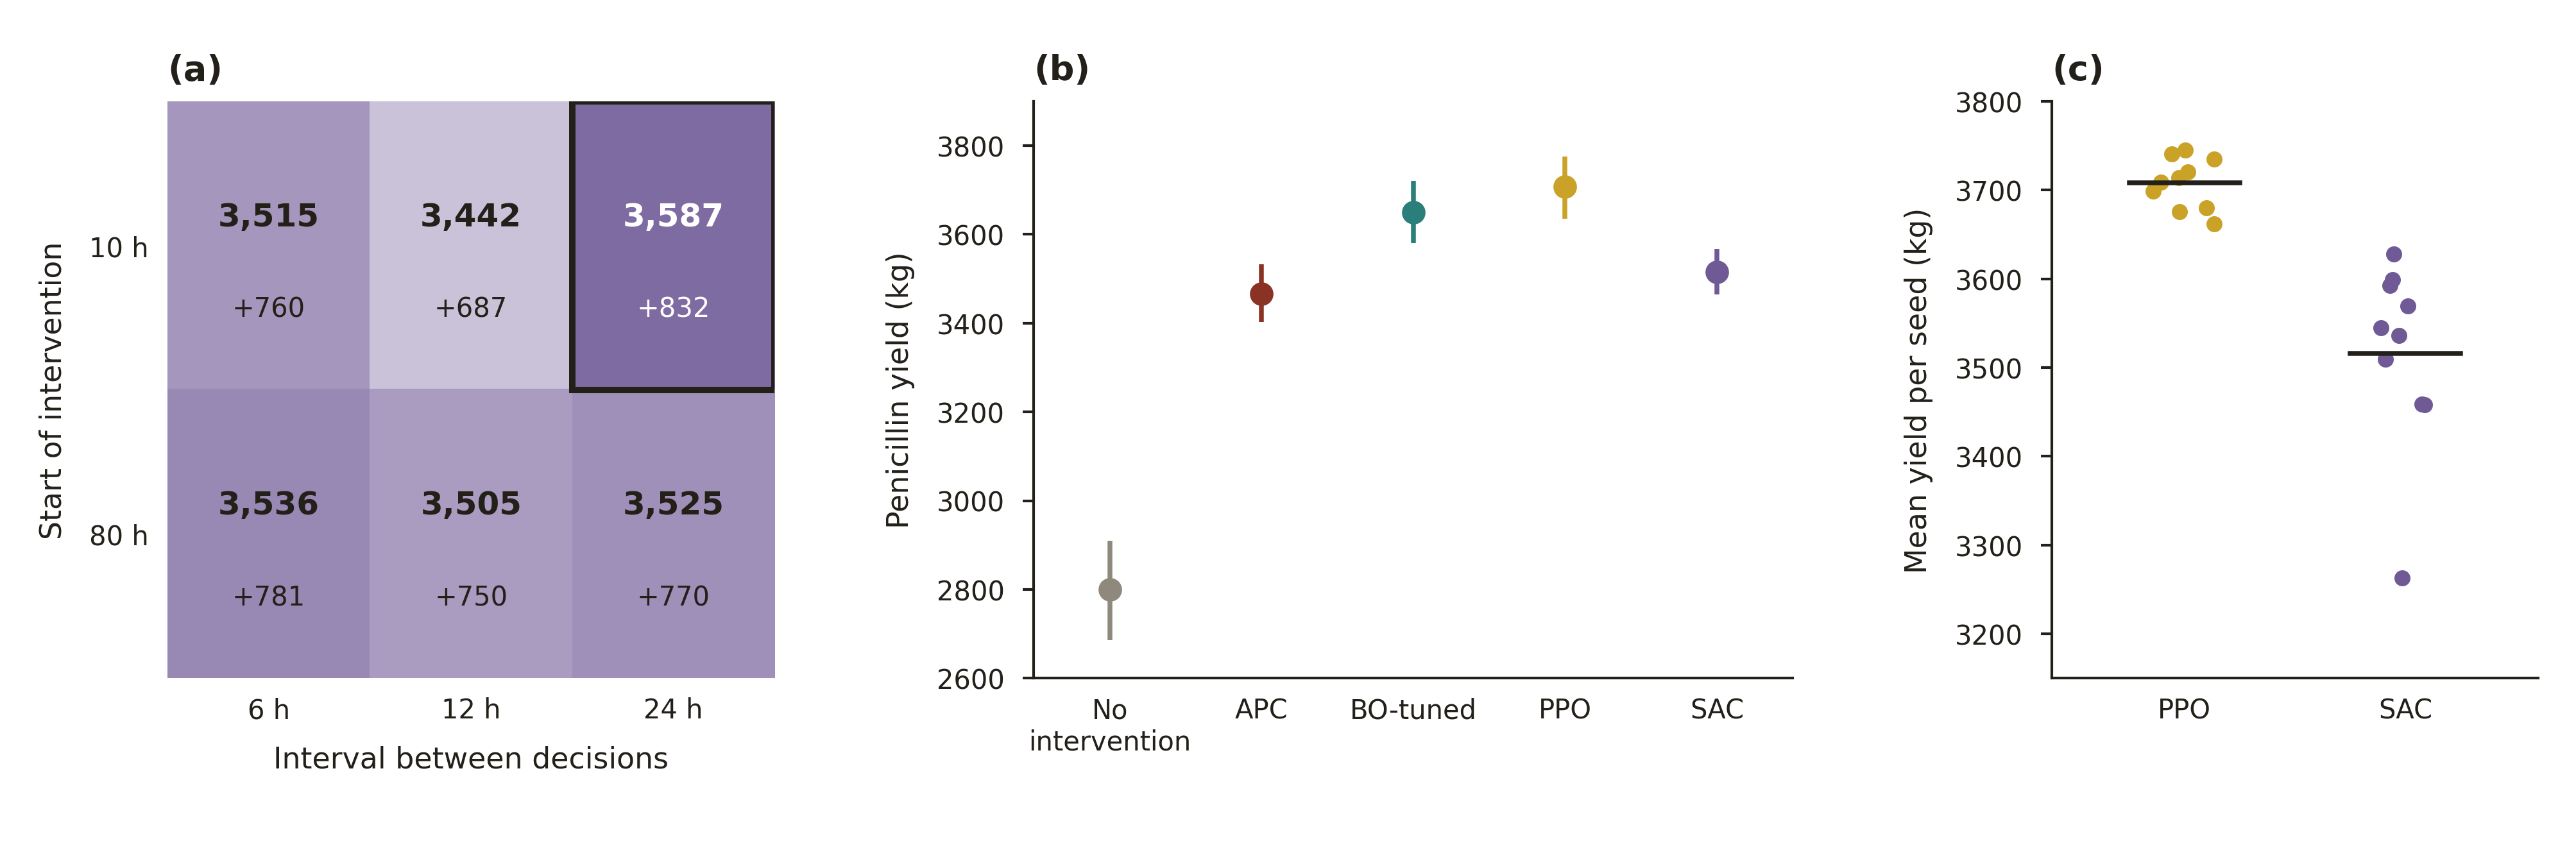

In [3]:
from IPython.display import Image
Image(OUTD + 'figS1.png', width=900)